# Shopping Behavior: Who Subscribes?

**Question:** what customer traits and shopping behaviors predict which customers become subscribers?

**Data:** 3,900 retail purchases (`shopping_behavior_updated.csv`, a public Kaggle dataset) with customer age, gender, location, item, category, amount, season, review rating, shipping type, payment method, purchase frequency, discount and promo code use, and subscription status.

**Approach:** explore the customer base and shopping patterns, train a random forest to predict subscription status, then test whether the model's accuracy comes from real behavior or from columns that give the answer away.

**Key results:**
- The random forest is 81.0% accurate and catches 89.6% of subscribers, which looks strong against the 73% "always guess no" baseline.
- But in this dataset every subscriber used a discount and a promo code, and every subscriber is male. Those two columns carry 45% of the model's feature importance.
- Without discount, promo code and gender, the model cannot find a single subscriber (71.3% accuracy vs. a 71.5% baseline on the test set). Nothing else in the data predicts who subscribes.
- Shopping patterns are remarkably even: purchase frequency, spending and category barely differ by age, gender or channel.

**Tools:** Python (pandas, scikit-learn, matplotlib, seaborn)

**Context:** master's coursework (DSC680, Project 1), cleaned up and corrected for this portfolio.

## 1. Load and check the data

In [1]:
# import required libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

In [2]:
df_shopping = pd.read_csv('shopping_behavior_updated.csv')
print(df_shopping.shape)
print('Missing values:', df_shopping.isna().sum().sum())
df_shopping.head()

(3900, 18)
Missing values: 0


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
df_shopping.describe().round(1)

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.0,3900.0,3900.0,3900.0,3900.0
mean,1950.5,44.1,59.8,3.7,25.4
std,1126.0,15.2,23.7,0.7,14.4
min,1.0,18.0,20.0,2.5,1.0
25%,975.8,31.0,39.0,3.1,13.0
50%,1950.5,44.0,60.0,3.7,25.0
75%,2925.2,57.0,81.0,4.4,38.0
max,3900.0,70.0,100.0,5.0,50.0


In [4]:
# number of distinct values in each text column
df_shopping.select_dtypes(include='object').nunique()

Gender                     2
Item Purchased            25
Category                   4
Location                  50
Size                       4
Color                     25
Season                     4
Subscription Status        2
Shipping Type              6
Discount Applied           2
Promo Code Used            2
Payment Method             6
Frequency of Purchases     7
dtype: int64

## 2. Feature engineering

In [5]:
# turn purchase frequency into an approximate number of purchases per year
freq_map = {'Weekly': 52, 'Bi-Weekly': 26, 'Fortnightly': 26, 'Monthly': 12,
            'Every 3 Months': 4, 'Quarterly': 4, 'Annually': 1}
df_shopping['Purchases_Per_Year'] = df_shopping['Frequency of Purchases'].map(freq_map)

# age groups and a simple channel flag (store pickup vs. shipped)
df_shopping['Age Group'] = pd.cut(df_shopping['Age'], bins=[18, 30, 45, 60, 75],
                                  labels=['18-30', '31-45', '46-60', '61-75'], right=False)
df_shopping['Channel'] = np.where(df_shopping['Shipping Type'] == 'Store Pickup', 'Store pickup', 'Shipped')

## 3. Who are the customers and how do they shop?

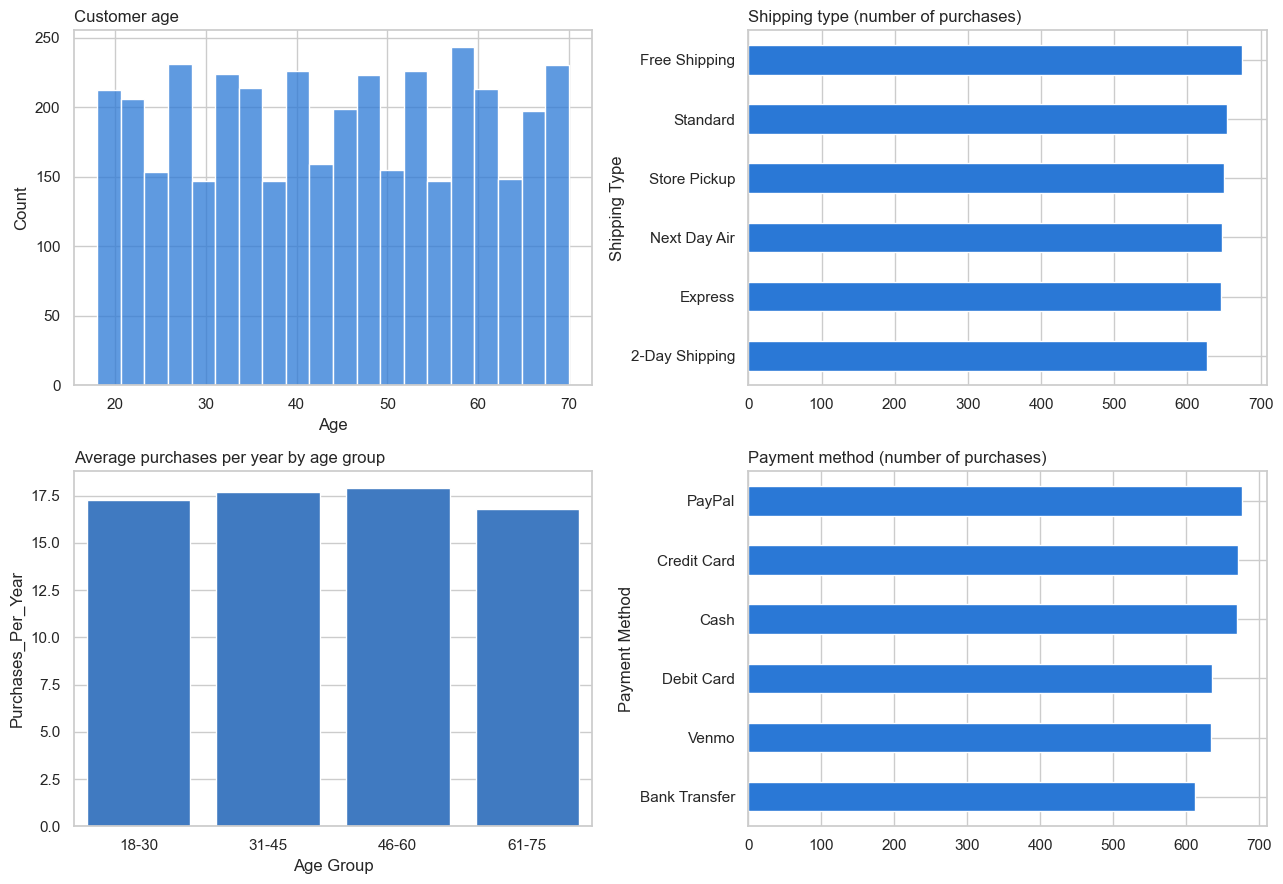

Channel share: {'Shipped': 0.833, 'Store pickup': 0.167}
Average purchases per year by age group: {'18-30': 17.3, '31-45': 17.7, '46-60': 17.9, '61-75': 16.8}
Average purchases per year by gender: {'Female': 17.5, 'Male': 17.4}
Average purchase amount by category ($): {'Accessories': 59.84, 'Clothing': 60.03, 'Footwear': 60.26, 'Outerwear': 57.17}


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(df_shopping['Age'], bins=20, ax=axes[0, 0], color='#2a78d6')
axes[0, 0].set_title('Customer age', loc='left')

df_shopping['Shipping Type'].value_counts().plot(kind='barh', ax=axes[0, 1], color='#2a78d6')
axes[0, 1].set_title('Shipping type (number of purchases)', loc='left'); axes[0, 1].invert_yaxis()

sns.barplot(x='Age Group', y='Purchases_Per_Year', data=df_shopping, ax=axes[1, 0], color='#2a78d6', errorbar=None)
axes[1, 0].set_title('Average purchases per year by age group', loc='left')

df_shopping['Payment Method'].value_counts().plot(kind='barh', ax=axes[1, 1], color='#2a78d6')
axes[1, 1].set_title('Payment method (number of purchases)', loc='left'); axes[1, 1].invert_yaxis()
plt.tight_layout()
plt.show()

print('Channel share:', df_shopping['Channel'].value_counts(normalize=True).round(3).to_dict())
print('Average purchases per year by age group:', df_shopping.groupby('Age Group', observed=True)['Purchases_Per_Year'].mean().round(1).to_dict())
print('Average purchases per year by gender:', df_shopping.groupby('Gender')['Purchases_Per_Year'].mean().round(1).to_dict())
print('Average purchase amount by category ($):', df_shopping.groupby('Category')['Purchase Amount (USD)'].mean().round(2).to_dict())

## 4. Predicting subscription status
Subscribers are the most valuable customers, so the question is which customer traits and behaviors predict who subscribes. About 27% of customers subscribe, so always guessing "not a subscriber" would already be 73% accurate. A useful model has to beat that.

In [7]:
# encode every text column as numbers for the random forest
model_df = df_shopping.copy()
le = LabelEncoder()
for col in model_df.select_dtypes(include='object').columns:
    model_df[col] = le.fit_transform(model_df[col].astype(str))

# drop the ID, the derived columns, and the target itself
drop_cols = ['Customer ID', 'Purchases_Per_Year', 'Age Group', 'Channel', 'Subscription Status']
X = model_df.drop(columns=drop_cols)
y = model_df['Subscription Status']          # 1 = subscriber
baseline = 1 - y.mean()
print(f'Subscribers: {y.mean():.1%}   Baseline accuracy (always "no"): {baseline:.1%}')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print(f'Random forest accuracy, all features: {accuracy_score(y_test, rf_pred):.1%}')
print(classification_report(y_test, rf_pred, target_names=['Not subscriber', 'Subscriber'], digits=3))

Subscribers: 27.0%   Baseline accuracy (always "no"): 73.0%


Random forest accuracy, all features: 81.0%
                precision    recall  f1-score   support

Not subscriber      0.950     0.776     0.854       558
    Subscriber      0.614     0.896     0.729       222

      accuracy                          0.810       780
     macro avg      0.782     0.836     0.791       780
  weighted avg      0.854     0.810     0.818       780



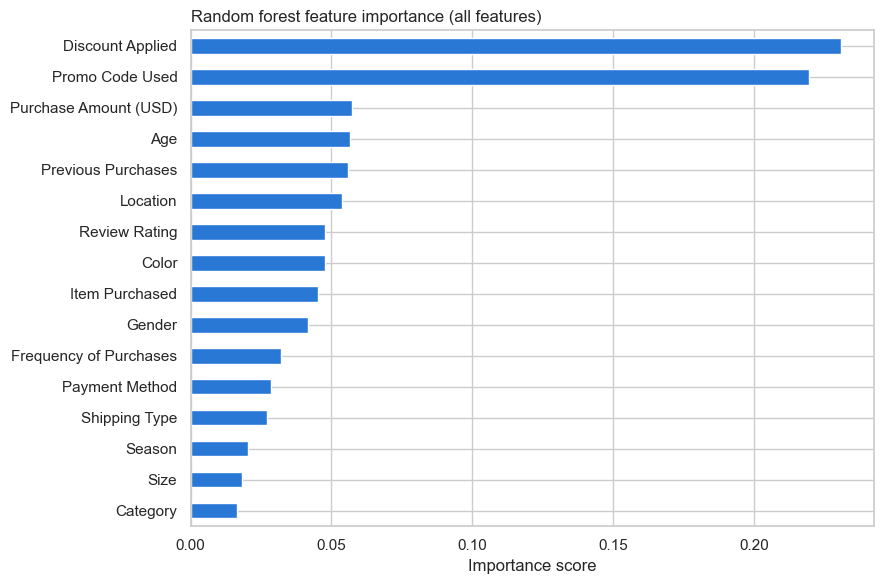

In [8]:
feat_importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(9, 6))
feat_importances.plot(kind='barh', color='#2a78d6')
plt.title('Random forest feature importance (all features)', loc='left')
plt.xlabel('Importance score')
plt.tight_layout()
plt.show()

## 5. Checking for giveaway features
A model can look accurate because one of its inputs is really part of the answer. Discount use, promo code use and gender are checked against subscription status below.

In [9]:
for col in ['Discount Applied', 'Promo Code Used', 'Gender']:
    print(pd.crosstab(df_shopping['Subscription Status'], df_shopping[col]), '\n')

Discount Applied       No   Yes
Subscription Status            
No                   2223   624
Yes                     0  1053 

Promo Code Used        No   Yes
Subscription Status            
No                   2223   624
Yes                     0  1053 

Gender               Female  Male
Subscription Status              
No                     1248  1599
Yes                       0  1053 



In [10]:
# refit without the three giveaway columns to see what the remaining behavior can predict
leaky = ['Discount Applied', 'Promo Code Used', 'Gender']
X2_train, X2_test = X_train.drop(columns=leaky), X_test.drop(columns=leaky)
rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X2_train, y_train)
rf2_pred = rf2.predict(X2_test)

test_baseline = 1 - y_test.mean()
comparison = pd.DataFrame({
    'accuracy': [test_baseline, accuracy_score(y_test, rf_pred), accuracy_score(y_test, rf2_pred)],
    'subscribers caught (recall)': [0.0, (rf_pred[y_test == 1] == 1).mean(), (rf2_pred[y_test == 1] == 1).mean()],
}, index=['Baseline: always "not a subscriber"', 'Random forest, all features', 'Random forest, without discount/promo/gender'])
comparison.round(3)

,accuracy,subscribers caught (recall)
"Baseline: always ""not a subscriber""",0.715,0.000
"Random forest, all features",0.810,0.896
"Random forest, without discount/promo/gender",0.713,0.000


## Findings
- **The model's accuracy comes from giveaway columns.** All 1,053 subscribers used a discount and a promo code, and all of them are male; no woman in the data is a subscriber. Discounts and promo codes are most likely subscriber perks recorded after the fact, so they describe subscribers rather than predict them. Together they carry 45% of the random forest's importance (0.231 and 0.220); no other feature is above 0.06.
- **Without those columns, nothing predicts subscription.** Retrained without discount, promo code and gender, the model predicts that no one subscribes: 71.3% accuracy against a 71.5% baseline on the test set, with zero subscribers caught. Age, location, spending, item, season, shipping type and payment method carry no usable signal.
- **Shopping patterns are very even across groups.** Average purchases per year range only from 16.8 to 17.9 across age groups and are 17.5 vs. 17.4 for women and men. Average purchase amounts by category fall between $57.17 (outerwear) and $60.26 (footwear). 83.3% of purchases are shipped and 16.7% are store pickups.
- **What this means:** the dataset is likely synthetic or heavily simplified, so it cannot support real conclusions about what drives subscriptions. The useful lesson is the method: checking how a model gets its accuracy before trusting it.
- **Next steps with real data:** record when a discount was given relative to subscribing, so perks are not used to predict the thing that earns them, and add behavior over time (visit frequency, browsing, returns) that could genuinely signal intent.

**Correction note:** the original version reported the 81% accuracy and the feature importance chart without noting that discount and promo code use perfectly separate subscribers from most non-subscribers. This version adds the leakage check and the model without those columns. The original notebook, plus a file labeled as this project's EDA that turned out to be a copy of the child care notebook, are in `earlier_versions/`.